In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate
%matplotlib inline

In [ ]:
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.cluster import KMeans

## **DATA**

In [ ]:
path1 = '/content/gdrive/MyDrive/GAIAData/80-20/TmaxData_2010_2014.xlsx'
train_data = pd.read_excel(path1)
train_data

,Date,Latitude,Longitude,IMD,NASA
0,2010-01-01,9.5,77.5,30.670000,29.19
1,2010-01-02,9.5,77.5,30.670000,28.98
2,2010-01-03,9.5,77.5,30.600000,28.71
3,2010-01-04,9.5,77.5,30.320000,29.55
4,2010-01-05,9.5,77.5,30.469999,30.91
...,...,...,...,...,...
18245,2014-12-27,11.5,79.5,28.343775,26.24
18246,2014-12-28,11.5,79.5,27.318331,26.23
18247,2014-12-29,11.5,79.5,28.781235,27.74
18248,2014-12-30,11.5,79.5,30.213234,29.59


In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18250 entries, 0 to 18249
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       18250 non-null  datetime64[ns]
 1   Latitude   18250 non-null  float64       
 2   Longitude  18250 non-null  float64       
 3   IMD        18250 non-null  float64       
 4   NASA       18250 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 713.0 KB


In [ ]:
train_data['Month'] = pd.to_datetime(train_data['Date']).dt.month
train_data

,Date,Latitude,Longitude,IMD,NASA,Month
0,2010-01-01,9.5,77.5,30.670000,29.19,1
1,2010-01-02,9.5,77.5,30.670000,28.98,1
2,2010-01-03,9.5,77.5,30.600000,28.71,1
3,2010-01-04,9.5,77.5,30.320000,29.55,1
4,2010-01-05,9.5,77.5,30.469999,30.91,1
...,...,...,...,...,...,...
18245,2014-12-27,11.5,79.5,28.343775,26.24,12
18246,2014-12-28,11.5,79.5,27.318331,26.23,12
18247,2014-12-29,11.5,79.5,28.781235,27.74,12
18248,2014-12-30,11.5,79.5,30.213234,29.59,12


## **DATA PREP**

In [ ]:
season_mapping = {
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Pre-Summer',
    4: 'Pre-Summer',
    5: 'Summer',
    6: 'Summer',
    7: 'Southwest Monsoon',
    8: 'Southwest Monsoon',
    9: 'Autumn',
    10: 'Autumn',
    11: 'Northeast Monsoon'
}

In [ ]:
train_data['season'] = train_data['Month'].map(season_mapping)
train_data

,Date,Latitude,Longitude,IMD,NASA,Month,season
0,2010-01-01,9.5,77.5,30.670000,29.19,1,Winter
1,2010-01-02,9.5,77.5,30.670000,28.98,1,Winter
2,2010-01-03,9.5,77.5,30.600000,28.71,1,Winter
3,2010-01-04,9.5,77.5,30.320000,29.55,1,Winter
4,2010-01-05,9.5,77.5,30.469999,30.91,1,Winter
...,...,...,...,...,...,...,...
18245,2014-12-27,11.5,79.5,28.343775,26.24,12,Winter
18246,2014-12-28,11.5,79.5,27.318331,26.23,12,Winter
18247,2014-12-29,11.5,79.5,28.781235,27.74,12,Winter
18248,2014-12-30,11.5,79.5,30.213234,29.59,12,Winter


In [ ]:
one_hot_encoded = pd.get_dummies(train_data['season'])

In [ ]:
train_encoded = pd.concat([train_data, one_hot_encoded], axis=1)
train_encoded

,Date,Latitude,Longitude,IMD,NASA,Month,season,Autumn,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter
0,2010-01-01,9.5,77.5,30.670000,29.19,1,Winter,False,False,False,False,False,True
1,2010-01-02,9.5,77.5,30.670000,28.98,1,Winter,False,False,False,False,False,True
2,2010-01-03,9.5,77.5,30.600000,28.71,1,Winter,False,False,False,False,False,True
3,2010-01-04,9.5,77.5,30.320000,29.55,1,Winter,False,False,False,False,False,True
4,2010-01-05,9.5,77.5,30.469999,30.91,1,Winter,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18245,2014-12-27,11.5,79.5,28.343775,26.24,12,Winter,False,False,False,False,False,True
18246,2014-12-28,11.5,79.5,27.318331,26.23,12,Winter,False,False,False,False,False,True
18247,2014-12-29,11.5,79.5,28.781235,27.74,12,Winter,False,False,False,False,False,True
18248,2014-12-30,11.5,79.5,30.213234,29.59,12,Winter,False,False,False,False,False,True


# **ALTITUDE WITH LAT AND LON**

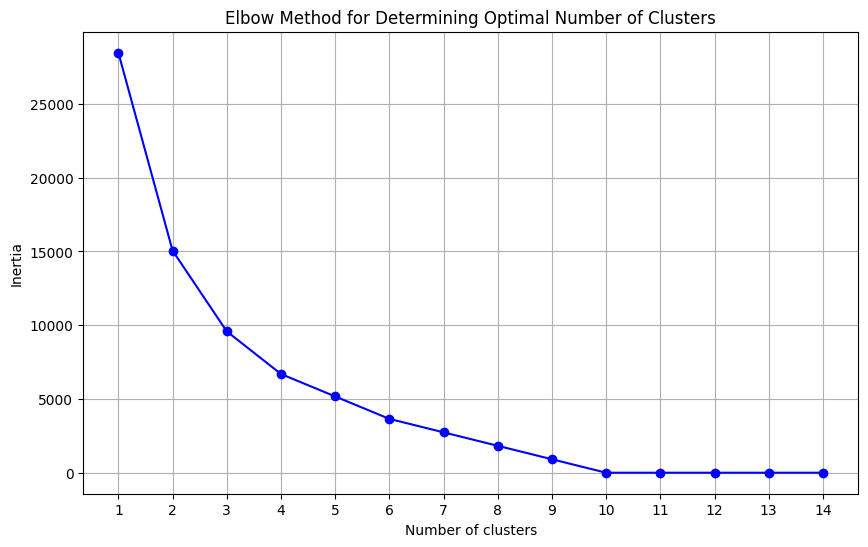

In [ ]:
coordinates = train_encoded[['Latitude', 'Longitude']]

cluster_range = range(1, 15)

# Initialize list to store the inertias (within-cluster sum of squares)
inertias = []

# Calculate the inertia for each number of clusters
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(coordinates)
    inertias.append(kmeans.inertia_)

# Plot the elbow graph
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, inertias, '-o', color='blue')
plt.title('Elbow Method for Determining Optimal Number of Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

lowest_k = inertias.index(min(inertias)) + 1

In [ ]:
# Function to apply KMeans clustering
def apply_kmeans(X, n_clusters):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    clusters = kmeans.fit_predict(X[['Latitude', 'Longitude']])
    X_new = X.copy()
    X_new['Cluster'] = clusters
    return pd.get_dummies(X_new, columns=['Cluster'])

In [ ]:
data_after_kmeans = apply_kmeans(train_encoded, n_clusters = lowest_k)
data_after_kmeans

,Date,Latitude,Longitude,IMD,NASA,Month,season,Autumn,Northeast Monsoon,Pre-Summer,...,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9
0,2010-01-01,9.5,77.5,30.670000,29.19,1,Winter,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,2010-01-02,9.5,77.5,30.670000,28.98,1,Winter,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,2010-01-03,9.5,77.5,30.600000,28.71,1,Winter,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,2010-01-04,9.5,77.5,30.320000,29.55,1,Winter,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,2010-01-05,9.5,77.5,30.469999,30.91,1,Winter,False,False,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18245,2014-12-27,11.5,79.5,28.343775,26.24,12,Winter,False,False,False,...,False,False,False,False,False,False,False,True,False,False
18246,2014-12-28,11.5,79.5,27.318331,26.23,12,Winter,False,False,False,...,False,False,False,False,False,False,False,True,False,False
18247,2014-12-29,11.5,79.5,28.781235,27.74,12,Winter,False,False,False,...,False,False,False,False,False,False,False,True,False,False
18248,2014-12-30,11.5,79.5,30.213234,29.59,12,Winter,False,False,False,...,False,False,False,False,False,False,False,True,False,False


## **TRAIN_TEST DATA**

In [ ]:
data_after_kmeans = data_after_kmeans.drop(['Month', 'season','Autumn', 'Date', 'IMD', 'Latitude', 'Longitude'], axis = 1)
data_after_kmeans

,NASA,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9
0,29.19,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
1,28.98,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
2,28.71,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
3,29.55,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
4,30.91,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18245,26.24,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18246,26.23,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18247,27.74,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18248,29.59,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False


In [ ]:
X = data_after_kmeans
y = train_encoded['IMD']

X

,NASA,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9
0,29.19,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
1,28.98,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
2,28.71,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
3,29.55,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
4,30.91,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18245,26.24,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18246,26.23,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18247,27.74,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False
18248,29.59,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False


In [ ]:
X_train, X_test, Y_train,Y_test = train_test_split(X, y, train_size = 0.8, shuffle =  True, random_state = 99)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## **Linear Regression**

In [ ]:
model = LinearRegression()
model.fit(X_train, Y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.408123066940247
Training MAE:  0.9144154048069673
Training R2:  0.8267626848708376


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.4748864172302116
Training MAE:  0.9293734376602989
Test R2:  0.8249166143370532


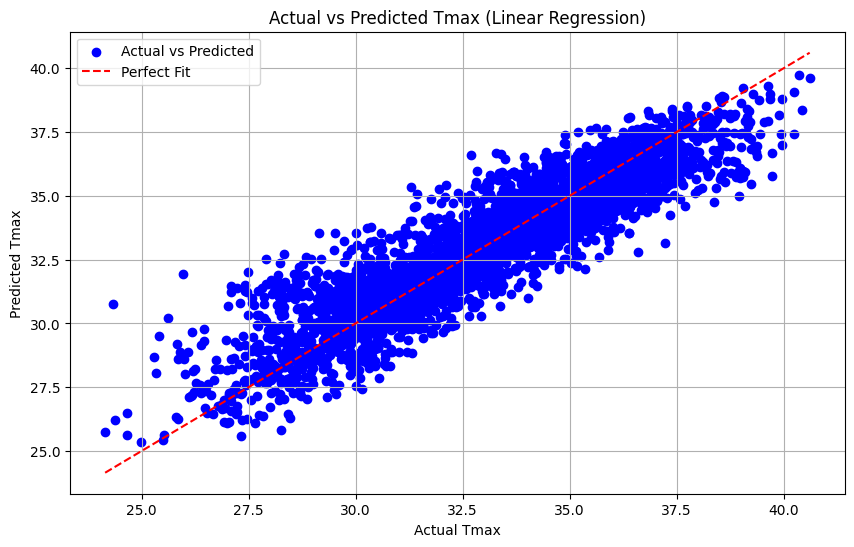

In [ ]:
# prompt: plot

# Plot the actual and predicted values for the test data
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Linear Regression)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
result1 = []
result1.append('Linear Regression')
result1.append(metrics.mean_squared_error(Y_train, y_train_pred))
result1.append(metrics.mean_absolute_error(Y_train, y_train_pred))
result1.append(metrics.r2_score(Y_train, y_train_pred))
result1.append(metrics.mean_squared_error(Y_test, y_test_pred))
result1.append(metrics.mean_absolute_error(Y_test, y_test_pred))
result1.append(metrics.r2_score(Y_test, y_test_pred))

In [ ]:
print("Linear Regression Coefficients:")
print(model.coef_)

Linear Regression Coefficients:
[ 1.68002044 -0.39738963  0.16912958  0.10197463  0.51934471 -0.66255149
  0.59149561  0.1427782  -0.50943355  0.26077219 -0.17173225  0.61248204
  0.09678926  0.03249695 -0.87791222 -0.18610376]


In [ ]:
model.intercept_

32.95789601615798

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted TMAX = {model.intercept_:.2f}"
for i, coef in enumerate(model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted TMAX = 32.96 + 1.68 * NASA + -0.40 * Northeast Monsoon + 0.17 * Pre-Summer + 0.10 * Southwest Monsoon + 0.52 * Summer + -0.66 * Winter + 0.59 * Cluster_0 + 0.14 * Cluster_1 + -0.51 * Cluster_2 + 0.26 * Cluster_3 + -0.17 * Cluster_4 + 0.61 * Cluster_5 + 0.10 * Cluster_6 + 0.03 * Cluster_7 + -0.88 * Cluster_8 + -0.19 * Cluster_9


## **LINEAR REGRESSION - RIDGE**


In [ ]:
ridge_model = Ridge(alpha=0.5)
ridge_model.fit(X_train, Y_train)

ridge_y_train_pred = ridge_model.predict(X_train)
ridge_y_test_pred = ridge_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.4081230769201094
Training MAE:  0.9144143850150253
Training R2:  0.826762683643044


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.4748905077029622
Training MAE:  0.929375282006503
Test R2:  0.8249161287580895


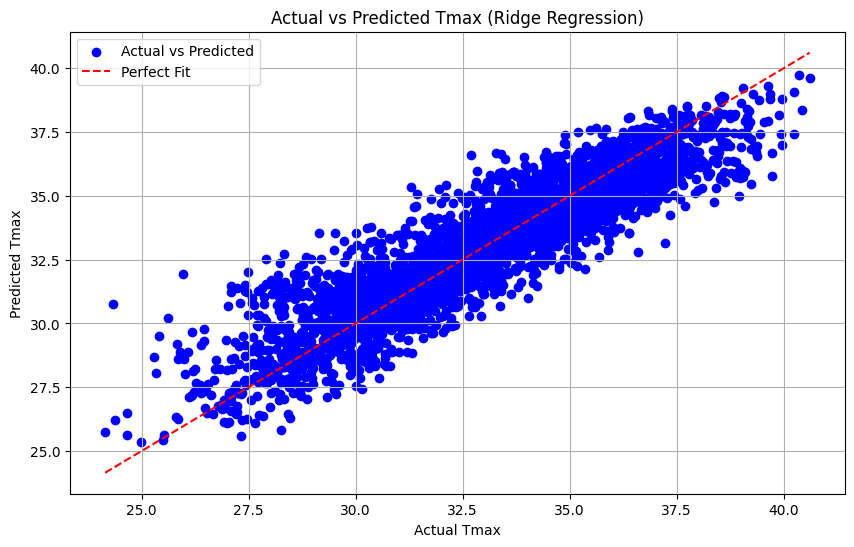

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Ridge Regression)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print("Ridge Regression (a = 0.5) Coefficients:")
print(ridge_model.coef_)

Ridge Regression (a = 0.5) Coefficients:
[ 1.67988928 -0.39739737  0.1691871   0.10199782  0.51937296 -0.66254697
  0.59143922  0.14278214 -0.50942418  0.26077793 -0.17173833  0.61243627
  0.0968109   0.0325121  -0.87787227 -0.1860909 ]


In [ ]:
ridge_model.intercept_

32.95789601615798

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted TMAX = {ridge_model.intercept_:.2f}"
for i, coef in enumerate(ridge_model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted TMAX = 32.96 + 1.68 * NASA + -0.40 * Northeast Monsoon + 0.17 * Pre-Summer + 0.10 * Southwest Monsoon + 0.52 * Summer + -0.66 * Winter + 0.59 * Cluster_0 + 0.14 * Cluster_1 + -0.51 * Cluster_2 + 0.26 * Cluster_3 + -0.17 * Cluster_4 + 0.61 * Cluster_5 + 0.10 * Cluster_6 + 0.03 * Cluster_7 + -0.88 * Cluster_8 + -0.19 * Cluster_9


In [ ]:
ridge_model_2 = Ridge()
ridge_model_2.fit(X_train, Y_train)

ridge_y_train_pred_2 = ridge_model_2.predict(X_train)
ridge_y_test_pred_2 = ridge_model_2.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred_2))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred_2))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred_2))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred_2))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred_2))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred_2))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.4081231068515263
Training MAE:  0.9144133651111948
Training R2:  0.8267626799606681


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.4748946173630346
Training MAE:  0.9293771258782153
Test R2:  0.8249156409014037


In [ ]:
# prompt: PLOT

# Plot the actual and predicted values for the test data
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred_2, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Ridge Regression)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print("Ridge Regression (a = 1) Coefficients:")
print(ridge_model_2.coef_)

Ridge Regression (a = 1) Coefficients:
[ 1.67975815 -0.3974051   0.16924459  0.10202099  0.51940119 -0.66254245
  0.59138284  0.14278607 -0.50941481  0.26078367 -0.17174441  0.61239051
  0.09683253  0.03252725 -0.87783232 -0.18607805]


In [ ]:
ridge_model_2.intercept_

32.95789601615798

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted TMAX = {ridge_model_2.intercept_:.2f}"
for i, coef in enumerate(ridge_model_2.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted TMAX = 32.96 + 1.68 * NASA + -0.40 * Northeast Monsoon + 0.17 * Pre-Summer + 0.10 * Southwest Monsoon + 0.52 * Summer + -0.66 * Winter + 0.59 * Cluster_0 + 0.14 * Cluster_1 + -0.51 * Cluster_2 + 0.26 * Cluster_3 + -0.17 * Cluster_4 + 0.61 * Cluster_5 + 0.10 * Cluster_6 + 0.03 * Cluster_7 + -0.88 * Cluster_8 + -0.19 * Cluster_9


In [ ]:
ridge_model_3 = Ridge(alpha=0.0001)
ridge_model_3.fit(X_train, Y_train)

ridge_y_train_pred_3 = ridge_model_3.predict(X_train)
ridge_y_test_pred_3 = ridge_model_3.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred_3))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred_3))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred_3))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred_3))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred_3))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred_3))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.4081230669402476
Training MAE:  0.91441540460302
Training R2:  0.8267626848708375


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.474886418046387
Training MAE:  0.9293734380292156
Test R2:  0.8249166142401653


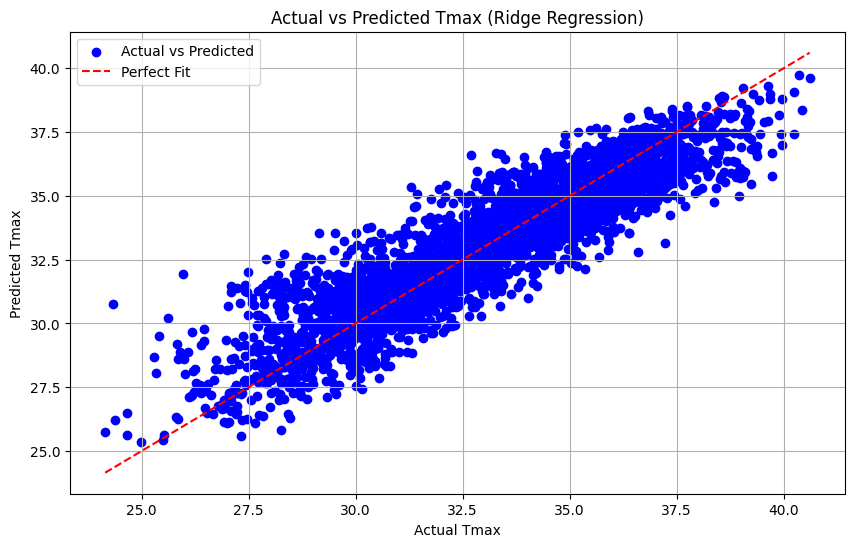

In [ ]:
# prompt: plot

# Plot the actual and predicted values for the test data
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred_3, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Ridge Regression)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print("Ridge Regression (a = 0.0001) Coefficients:")
print(ridge_model.coef_)

Ridge Regression (a = 0.0001) Coefficients:
[ 1.67988928 -0.39739737  0.1691871   0.10199782  0.51937296 -0.66254697
  0.59143922  0.14278214 -0.50942418  0.26077793 -0.17173833  0.61243627
  0.0968109   0.0325121  -0.87787227 -0.1860909 ]


In [ ]:
ridge_model_3.intercept_

32.95789601615798

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted TMAX = {ridge_model_3.intercept_:.2f}"
for i, coef in enumerate(ridge_model_3.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted TMAX = 32.96 + 1.68 * NASA + -0.40 * Northeast Monsoon + 0.17 * Pre-Summer + 0.10 * Southwest Monsoon + 0.52 * Summer + -0.66 * Winter + 0.59 * Cluster_0 + 0.14 * Cluster_1 + -0.51 * Cluster_2 + 0.26 * Cluster_3 + -0.17 * Cluster_4 + 0.61 * Cluster_5 + 0.10 * Cluster_6 + 0.03 * Cluster_7 + -0.88 * Cluster_8 + -0.19 * Cluster_9


In [ ]:
result2 = []
result2.append('Linear Regression - Ridge (Alpha = 0.5)')
result2.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred))
result2.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
result2.append(metrics.r2_score(Y_train, ridge_y_train_pred))
result2.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred))
result2.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
result2.append(metrics.r2_score(Y_test, ridge_y_test_pred))

result3 = []
result3.append('Linear Regression - Ridge (Alpha = 1)')
result3.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred_2))
result3.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred_2))
result3.append(metrics.r2_score(Y_train, ridge_y_train_pred_2))
result3.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred_2))
result3.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred_2))
result3.append(metrics.r2_score(Y_test, ridge_y_test_pred_2))

result4 = []
result4.append('Linear Regression - Ridge (Alpha = 0.0001)')
result4.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred_3))
result4.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred_3))
result4.append(metrics.r2_score(Y_train, ridge_y_train_pred_3))
result4.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred_3))
result4.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred_3))
result4.append(metrics.r2_score(Y_test, ridge_y_test_pred_3))

# **LINEAR REGRESSION - LASSO**

In [ ]:
lasso_model = Lasso()
lasso_model.fit(X_train, Y_train)

lasso_y_train_pred = lasso_model.predict(X_train)
lasso_y_test_pred = lasso_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, lasso_y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, lasso_y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, lasso_y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, lasso_y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, lasso_y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, lasso_y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  5.497462242817098
Training MAE:  1.9328977689271105
Training R2:  0.32366309356823364


VALIDATION RESULTS
-------------------------------------
Test MSE:  5.741781020457944
Training MAE:  1.9695552942406251
Test R2:  0.3183946580205622


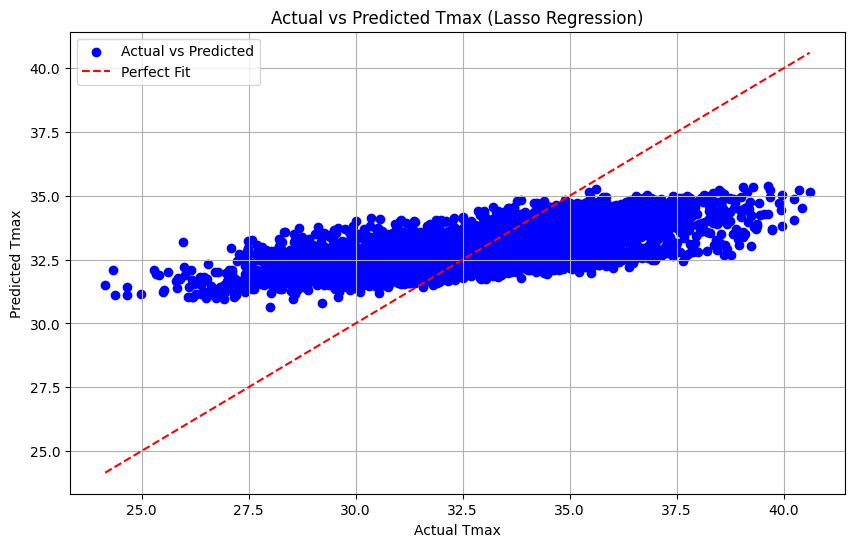

In [ ]:
# prompt: plot

# Plot the actual and predicted values for the test data
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, lasso_y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Lasso Regression)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print("Lasso Regression Coefficients:")
print(lasso_model.coef_)

Lasso Regression Coefficients:
[ 0.85436593 -0.          0.          0.          0.         -0.07231173
  0.          0.         -0.          0.         -0.          0.
  0.          0.         -0.         -0.        ]


In [ ]:
lasso_model.intercept_

32.95789601615798

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted TMAX = {lasso_model.intercept_:.2f}"
for i, coef in enumerate(lasso_model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted TMAX = 32.96 + 0.85 * NASA + -0.07 * Winter


In [ ]:
result5 = []
result5.append('Linear Regression - LASSO')
result5.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred))
result5.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
result5.append(metrics.r2_score(Y_train, ridge_y_train_pred))
result5.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred))
result5.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
result5.append(metrics.r2_score(Y_test, ridge_y_test_pred))

# **SUPPORT VECTOR MACHINE**

In [ ]:
svm_model = SVR(kernel='linear', C=1.0)
svm_model.fit(X_train, Y_train)

svm_train_pred = svm_model.predict(X_train)
svm_test_pred = svm_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, svm_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, svm_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, svm_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, svm_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, svm_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, svm_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.4217527841215034
Training MAE:  0.9099406904681392
Training R2:  0.8250858601202983


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.495684755224831
Training MAE:  0.9295873761636535
Test R2:  0.822447649005405


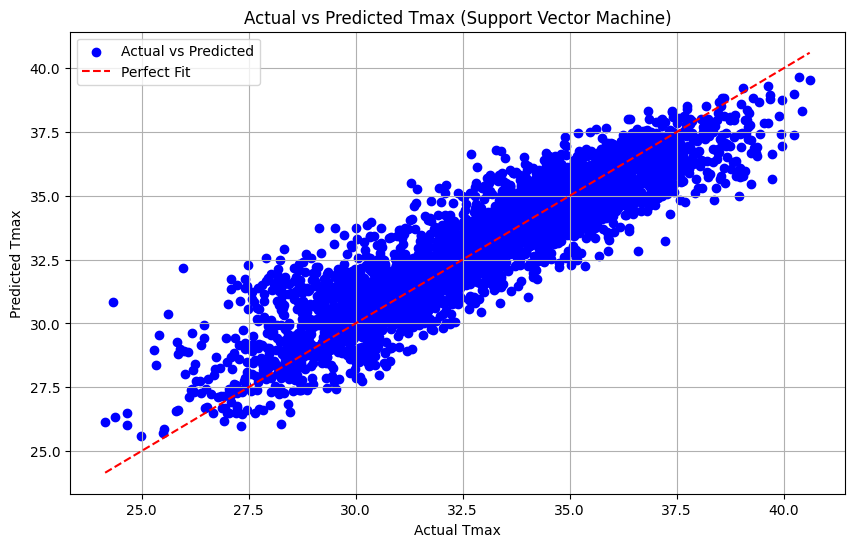

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, svm_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('Actual Tmax')
plt.ylabel('Predicted Tmax')
plt.title('Actual vs Predicted Tmax (Support Vector Machine)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print("SVM Coefficients:")
print(svm_model.coef_)

SVM Coefficients:
[[ 1.65037288 -0.3857427   0.13582663  0.09062406  0.51117118 -0.69753576
   0.6093161   0.13796148 -0.52724957  0.23126431 -0.17443527  0.63072729
   0.07428193  0.02714072 -0.82804008 -0.18950959]]


In [ ]:
svm_model.intercept_

array([33.02415764])

In [ ]:
equation = f"Predicted TMAX = {svm_model.intercept_[0]:.2f}"
for i, coef in enumerate(svm_model.coef_[0]):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")

Equation: Predicted TMAX = 33.02 + 1.65 * NASA + -0.39 * Northeast Monsoon + 0.14 * Pre-Summer + 0.09 * Southwest Monsoon + 0.51 * Summer + -0.70 * Winter + 0.61 * Cluster_0 + 0.14 * Cluster_1 + -0.53 * Cluster_2 + 0.23 * Cluster_3 + -0.17 * Cluster_4 + 0.63 * Cluster_5 + 0.07 * Cluster_6 + 0.03 * Cluster_7 + -0.83 * Cluster_8 + -0.19 * Cluster_9


In [ ]:
result6 = []
result6.append('Support Vector - SVM')
result6.append(metrics.mean_squared_error(Y_train, svm_train_pred))
result6.append(metrics.mean_absolute_error(Y_train, svm_train_pred))
result6.append(metrics.r2_score(Y_train, svm_train_pred))
result6.append(metrics.mean_squared_error(Y_test, svm_test_pred))
result6.append(metrics.mean_absolute_error(Y_test, svm_test_pred))
result6.append(metrics.r2_score(Y_test, svm_test_pred))

# **RESULTS**

In [ ]:
print(tabulate([result1,result2,result3,result4,result5,result6], headers=['METHOD', 'TRAIN MSE', 'TRAIN MAE', 'TRAIN R_SQUARED', 'TEST MSE', 'TEST MAE','TEST R-SQUARED']))

METHOD                                        TRAIN MSE    TRAIN MAE    TRAIN R_SQUARED    TEST MSE    TEST MAE    TEST R-SQUARED
------------------------------------------  -----------  -----------  -----------------  ----------  ----------  ----------------
Linear Regression                               1.40812     0.914415           0.826763     1.47489    0.929373          0.824917
Linear Regression - Ridge (Alpha = 0.5)         1.40812     0.914414           0.826763     1.47489    0.929375          0.824916
Linear Regression - Ridge (Alpha = 1)           1.40812     0.914413           0.826763     1.47489    0.929377          0.824916
Linear Regression - Ridge (Alpha = 0.0001)      1.40812     0.914415           0.826763     1.47489    0.929373          0.824917
Linear Regression - LASSO                       1.40812     0.914414           0.826763     1.47489    0.929375          0.824916
Support Vector - SVM                            1.42175     0.909941           0.825086   